# 09 — Zonal Classification and Region Comparison

## Objective

This notebook trains **Logistic Regression, Random Forest, and XGBoost** on radiomic features extracted separately from the peripheral zone (PZ), transition zone (TZ), and their concatenation (PZ + TZ).

The corrected grouped_v2 patient-level split and source labels used in notebooks 06–07 are maintained. For fair cohort comparisons, the original whole-gland feature table is restricted to the **identical cases** available in the zonal feature table.

**Interpretation warning:** The whole-gland baseline uses U-Net-predicted masks; PZ/TZ features use available anatomical reference masks. Therefore region and mask provenance are confounded. This study is an exploratory comparison, not proof of a zonal segmentation advantage.

## 1. Environment and Paths

Run from `notebooks/`. This notebook uses the classification environment (scikit-learn, XGBoost, matplotlib, joblib), not PyRadiomics.

In [1]:
from pathlib import Path
import json
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve, RocCurveDisplay, PrecisionRecallDisplay,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

PROJECT_ROOT = Path.cwd().parent
RANDOM_STATE = 42
features_dir = PROJECT_ROOT / "src" / "data" / "features"
zonal_path = features_dir / "zonal_t2w_radiomics_grouped_v2.csv"
whole_gland_path = features_dir / "whole_gland_t2w_radiomics_grouped_v2.csv"
clinical_path = PROJECT_ROOT / "src" / "data" / "raw" / "picai_labels" / "clinical_information" / "marksheet.csv"
splits_path = PROJECT_ROOT / "src" / "data" / "processed" / "splits" / "patient_splits_grouped_v2.csv"
results_dir = PROJECT_ROOT / "results" / "zonal_classification_grouped_v2"
results_dir.mkdir(parents=True, exist_ok=True)
for path in [zonal_path, whole_gland_path, clinical_path, splits_path]:
    if not path.is_file():
        raise FileNotFoundError(f"Required file missing: {path}")
print("Zonal features:", zonal_path)
print("Whole-gland features:", whole_gland_path)

Zonal features: c:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\src\data\features\zonal_t2w_radiomics_grouped_v2.csv
Whole-gland features: c:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\src\data\features\whole_gland_t2w_radiomics_grouped_v2.csv


## 2. Load and Validate Source Tables

Retain patient/study identifiers as strings. Use only the `case_csPCa` outcome and previously saved split labels.

In [2]:
id_columns = ["patient_id", "study_id"]
dtypes = {"patient_id": str, "study_id": str}
zonal_df = pd.read_csv(zonal_path, dtype=dtypes)
whole_df = pd.read_csv(whole_gland_path, dtype=dtypes)
clinical_df = pd.read_csv(clinical_path, dtype=dtypes)
splits_df = pd.read_csv(splits_path, dtype=dtypes)
for name, table in [("Zonal", zonal_df), ("Whole gland", whole_df), ("Clinical", clinical_df), ("Splits", splits_df)]:
    if not set(id_columns).issubset(table.columns):
        raise ValueError(f"Missing case identifiers in {name}")
    if table.duplicated(id_columns).any():
        raise ValueError(f"Duplicate patient-study pair in {name}")

pz_columns = [col for col in zonal_df if col.startswith("pz__")]
tz_columns = [col for col in zonal_df if col.startswith("tz__")]
wg_columns = [col for col in whole_df if col not in id_columns]
if (len(pz_columns), len(tz_columns), len(wg_columns)) != (107, 107, 107):
    raise ValueError(f"Unexpected feature counts: PZ={len(pz_columns)}, TZ={len(tz_columns)}, WG={len(wg_columns)}")

# Inner join ensures every evaluated region has exactly the same cases.
cohort = zonal_df.merge(whole_df, on=id_columns, how="inner", validate="one_to_one", suffixes=("", "_wg"))
cohort = cohort.merge(clinical_df[id_columns + ["case_csPCa"]], on=id_columns, how="left", validate="one_to_one")
cohort = cohort.merge(splits_df[id_columns + ["split"]], on=id_columns, how="left", validate="one_to_one")
if cohort[["case_csPCa", "split"]].isna().any().any():
    raise ValueError("Missing outcome or split in common cohort")
cohort["split"] = cohort["split"].astype(str).str.lower().str.strip().replace({"validation": "val"})
target_mapping = {"YES": 1, "NO": 0, "TRUE": 1, "FALSE": 0, "1": 1, "0": 0}
cohort["target"] = cohort["case_csPCa"].astype(str).str.upper().str.strip().map(target_mapping)
if cohort["target"].isna().any():
    raise ValueError("Unknown clinical target")
cohort["target"] = cohort["target"].astype(int)
if not set(cohort["split"]).issubset({"train", "val", "test"}):
    raise ValueError("Unknown saved split")
print("Zonal cases:", len(zonal_df), "Whole-gland cases:", len(whole_df), "Shared cohort:", len(cohort))
display(pd.crosstab(cohort["split"], cohort["target"]))
if cohort["split"].nunique() != 3 or cohort.groupby("split")["target"].nunique().min() < 2:
    raise ValueError("Each of train/val/test must contain both classes")

# Join adds '_wg' suffix only to overlapping feature names.
whole_columns_in_cohort = [col if col not in zonal_df.columns else f"{col}_wg" for col in wg_columns]
feature_groups = {
    "PZ": pz_columns,
    "TZ": tz_columns,
    "PZ + TZ": pz_columns + tz_columns,
    "Whole gland (predicted mask)": whole_columns_in_cohort,
}
for name, columns in feature_groups.items():
    if not set(columns).issubset(cohort.columns):
        raise ValueError(f"Missing features for {name}")
    cohort[columns] = cohort[columns].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    if cohort[columns].isna().all(axis=0).any():
        raise ValueError(f"Entirely missing feature column in {name}")
# Grouped-v2 integrity checks before fitting any model.
if len(cohort) != 1500:
    raise ValueError(f"Expected 1500 common exams; found {len(cohort)}")
expected_partition_counts = {"train": 1049, "val": 226, "test": 225}
actual_partition_counts = cohort["split"].value_counts().to_dict()
if actual_partition_counts != expected_partition_counts:
    raise ValueError(f"Unexpected grouped-v2 partition counts: {actual_partition_counts}")
patient_partition_count = cohort.groupby("patient_id")["split"].nunique()
if (patient_partition_count > 1).any():
    raise ValueError("Patient leakage detected between grouped-v2 splits")
expected_targets = {"train": {0: 752, 1: 297}, "val": {0: 162, 1: 64}, "test": {0: 161, 1: 64}}
for split_name, class_counts in expected_targets.items():
    actual = cohort.loc[cohort["split"] == split_name, "target"].value_counts().to_dict()
    if actual != class_counts:
        raise ValueError(f"Unexpected {split_name} clinical distribution: {actual}")
print("Grouped-v2 verified: 1500 exams, 1476 patients, no patient leakage")
print("Features and shared cohort verified")

Zonal cases: 1500 Whole-gland cases: 1500 Shared cohort: 1500


C:\Users\Luiz Trindade\AppData\Local\Temp\ipykernel_19412\3614153561.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  cohort["target"] = cohort["case_csPCa"].astype(str).str.upper().str.strip().map(target_mapping)


target,0,1
split,,
test,161,64
train,752,297
val,162,64


Grouped-v2 verified: 1500 exams, 1476 patients, no patient leakage
Features and shared cohort verified


## 3. Prepare Training, Validation and Test Sets

Do not regenerate splits or fit preprocessing on validation/test data. Candidate selection is based only on validation ROC-AUC.

In [3]:
datasets = {}
for region_name, columns in feature_groups.items():
    datasets[region_name] = {}
    for split_name in ["train", "val", "test"]:
        subset = cohort.loc[cohort["split"] == split_name]
        datasets[region_name][split_name] = (
            subset[columns].to_numpy(dtype=float),
            subset["target"].to_numpy(dtype=int),
        )
for region_name, partitions in datasets.items():
    print(region_name, {key: value[0].shape for key, value in partitions.items()})
cohort[id_columns + ["split", "target"]].to_csv(results_dir / "shared_cohort.csv", index=False)

PZ {'train': (1049, 107), 'val': (226, 107), 'test': (225, 107)}
TZ {'train': (1049, 107), 'val': (226, 107), 'test': (225, 107)}
PZ + TZ {'train': (1049, 214), 'val': (226, 214), 'test': (225, 214)}
Whole gland (predicted mask) {'train': (1049, 107), 'val': (226, 107), 'test': (225, 107)}


## 4. Candidate Models

The candidate ranges are deliberately modest to keep the experiment reproducible. Logistic Regression scales its inputs inside the training-only pipeline; tree models use median imputation. The class weight for XGBoost is calculated from **training cases only**.

In [4]:
y_train = datasets["PZ"]["train"][1]
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
positive_weight = negative_count / positive_count

def make_candidates():
    logistic = [
        (f"C={C}", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(
                C=C, class_weight="balanced", max_iter=3000,
                solver="liblinear", random_state=RANDOM_STATE,
            )),
        ])) for C in [0.01, 0.1, 1.0, 10.0]
    ]
    forest = [
        (f"trees={trees},depth={depth},leaf={leaf}", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("classifier", RandomForestClassifier(
                n_estimators=trees, max_depth=depth,
                min_samples_leaf=leaf, class_weight="balanced",
                random_state=RANDOM_STATE, n_jobs=-1,
            )),
        ])) for trees in [150, 300] for depth in [5, None] for leaf in [2, 5]
    ]
    xgboost = [
        (f"trees={trees},depth={depth}", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("classifier", XGBClassifier(
                n_estimators=trees, max_depth=depth,
                learning_rate=0.03, min_child_weight=10,
                reg_alpha=0.5, reg_lambda=10,
                subsample=0.8, colsample_bytree=0.8,
                scale_pos_weight=positive_weight,
                objective="binary:logistic", eval_metric="logloss",
                random_state=RANDOM_STATE, tree_method="hist",
                n_jobs=-1,
            )),
        ])) for trees in [100, 150] for depth in [2, 3]
    ]
    return {"Logistic Regression": logistic, "Random Forest": forest, "XGBoost": xgboost}

print("Training class counts:", negative_count, positive_count)
print("XGBoost class weight:", positive_weight)
print("Candidate counts:", {key: len(val) for key, val in make_candidates().items()})

Training class counts: 752 297
XGBoost class weight: 2.531986531986532
Candidate counts: {'Logistic Regression': 4, 'Random Forest': 8, 'XGBoost': 4}


## 5. Model Selection on Validation

Each region is evaluated using independently selected hyperparameters; no test scores are used to select candidate models.

In [5]:
selection_rows = []
selected = {}
for region_name, partitions in datasets.items():
    X_train, y_train = partitions["train"]
    X_val, y_val = partitions["val"]
    for model_name, candidates in make_candidates().items():
        best_auc = -np.inf
        for configuration, candidate in candidates:
            start = time.perf_counter()
            candidate.fit(X_train, y_train)
            elapsed = time.perf_counter() - start
            scores = candidate.predict_proba(X_val)[:, 1]
            auc = roc_auc_score(y_val, scores)
            selection_rows.append({
                "region": region_name, "model": model_name,
                "configuration": configuration, "validation_roc_auc": auc,
                "training_seconds": elapsed,
            })
            if auc > best_auc:
                best_auc = auc
                selected[(region_name, model_name)] = {
                    "model": candidate, "configuration": configuration,
                    "validation_roc_auc": auc,
                    "training_seconds": elapsed,
                }
        print(region_name, model_name, "best validation ROC-AUC:", round(best_auc, 4))
selection_df = pd.DataFrame(selection_rows)
display(selection_df.sort_values("validation_roc_auc", ascending=False).head(20))

PZ Logistic Regression best validation ROC-AUC: 0.6583
PZ Random Forest best validation ROC-AUC: 0.6644
PZ XGBoost best validation ROC-AUC: 0.6373
TZ Logistic Regression best validation ROC-AUC: 0.6648
TZ Random Forest best validation ROC-AUC: 0.6775
TZ XGBoost best validation ROC-AUC: 0.6635
PZ + TZ Logistic Regression best validation ROC-AUC: 0.6762
PZ + TZ Random Forest best validation ROC-AUC: 0.6822
PZ + TZ XGBoost best validation ROC-AUC: 0.6709
Whole gland (predicted mask) Logistic Regression best validation ROC-AUC: 0.6508
Whole gland (predicted mask) Random Forest best validation ROC-AUC: 0.6696
Whole gland (predicted mask) XGBoost best validation ROC-AUC: 0.6512


,region,model,configuration,validation_roc_auc,training_seconds
43,PZ + TZ,Random Forest,"trees=300,depth=None,leaf=5",0.682195,0.650052
39,PZ + TZ,Random Forest,"trees=150,depth=None,leaf=5",0.682099,0.339456
38,PZ + TZ,Random Forest,"trees=150,depth=None,leaf=2",0.679302,0.344859
27,TZ,Random Forest,"trees=300,depth=None,leaf=5",0.677469,0.675544
35,PZ + TZ,Logistic Regression,C=10.0,0.676215,0.251981
37,PZ + TZ,Random Forest,"trees=150,depth=5,leaf=5",0.673997,0.314917
22,TZ,Random Forest,"trees=150,depth=None,leaf=2",0.673900,0.321360
23,TZ,Random Forest,"trees=150,depth=None,leaf=5",0.673032,0.337550
36,PZ + TZ,Random Forest,"trees=150,depth=5,leaf=2",0.672357,0.325326
26,TZ,Random Forest,"trees=300,depth=None,leaf=2",0.672357,0.622316


### 5.1 Validation-Only Thresholds

Select the Youden threshold independently for each selected region/model combination.

In [6]:
def youden_threshold(y_true, scores):
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    valid = np.isfinite(thresholds)
    if not valid.any():
        raise ValueError("No finite threshold candidates")
    return float(thresholds[valid][np.argmax(tpr[valid] - fpr[valid])])

for (region_name, model_name), info in selected.items():
    X_val, y_val = datasets[region_name]["val"]
    val_scores = info["model"].predict_proba(X_val)[:, 1]
    info["threshold"] = youden_threshold(y_val, val_scores)
    print(region_name, model_name, "threshold:", round(info["threshold"], 5))

PZ Logistic Regression threshold: 0.43153
PZ Random Forest threshold: 0.36222
PZ XGBoost threshold: 0.58318
TZ Logistic Regression threshold: 0.39664
TZ Random Forest threshold: 0.46116
TZ XGBoost threshold: 0.39725
PZ + TZ Logistic Regression threshold: 0.43094
PZ + TZ Random Forest threshold: 0.45528
PZ + TZ XGBoost threshold: 0.49723
Whole gland (predicted mask) Logistic Regression threshold: 0.44318
Whole gland (predicted mask) Random Forest threshold: 0.56362
Whole gland (predicted mask) XGBoost threshold: 0.50659


## 6. Final Test Evaluation

**Execute only after** model/threshold selection has been frozen. Results from this test set must not be used to revise the candidate grids.

In [7]:
def evaluate_predictions(y_true, scores, threshold):
    predicted = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        "roc_auc": roc_auc_score(y_true, scores),
        "pr_auc": average_precision_score(y_true, scores),
        "sensitivity": recall_score(y_true, predicted, zero_division=0),
        "specificity": float(tn / (tn + fp)),
        "precision": precision_score(y_true, predicted, zero_division=0),
        "f1_score": f1_score(y_true, predicted, zero_division=0),
        "accuracy": accuracy_score(y_true, predicted),
        "balanced_accuracy": balanced_accuracy_score(y_true, predicted),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

metrics_rows = []
prediction_frames = []
for (region_name, model_name), info in selected.items():
    X_test, y_test = datasets[region_name]["test"]
    scores = info["model"].predict_proba(X_test)[:, 1]
    metrics_rows.append({
        "region": region_name, "model": model_name,
        "configuration": info["configuration"],
        "validation_roc_auc": info["validation_roc_auc"],
        "threshold": info["threshold"],
        **evaluate_predictions(y_test, scores, info["threshold"]),
    })
    test_cases = cohort.loc[cohort["split"] == "test", id_columns].copy()
    test_cases["region"] = region_name
    test_cases["model"] = model_name
    test_cases["target"] = y_test
    test_cases["score"] = scores
    test_cases["prediction"] = (scores >= info["threshold"]).astype(int)
    prediction_frames.append(test_cases)
metrics_df = pd.DataFrame(metrics_rows)
predictions_df = pd.concat(prediction_frames, ignore_index=True)
display(metrics_df[["region", "model", "roc_auc", "pr_auc", "sensitivity", "specificity", "f1_score", "balanced_accuracy"]].round(4))

,region,model,roc_auc,pr_auc,sensitivity,specificity,f1_score,balanced_accuracy
0,PZ,Logistic Regression,0.7228,0.5468,0.7188,0.5714,0.5140,0.6451
1,PZ,Random Forest,0.7033,0.5261,0.7344,0.4969,0.4896,0.6156
2,PZ,XGBoost,0.6744,0.4991,0.4219,0.7950,0.4355,0.6085
3,TZ,Logistic Regression,0.6665,0.4750,0.7344,0.3665,0.4413,0.5504
4,TZ,Random Forest,0.6390,0.4415,0.6094,0.5963,0.4643,0.6028
5,TZ,XGBoost,0.6480,0.4583,0.6875,0.4720,0.4560,0.5798
6,PZ + TZ,Logistic Regression,0.7081,0.5441,0.6562,0.6273,0.5060,0.6418
7,PZ + TZ,Random Forest,0.6876,0.5097,0.6562,0.6522,0.5185,0.6542
8,PZ + TZ,XGBoost,0.6953,0.5446,0.5625,0.6957,0.4832,0.6291
9,Whole gland (predicted mask),Logistic Regression,0.6852,0.4440,0.7812,0.5093,0.5181,0.6453


## 7. Visualizations

One ROC and PR curve per region, comparing the three classifiers on the shared test cohort.

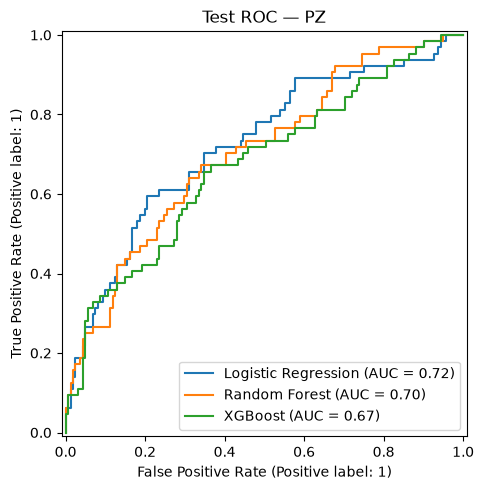

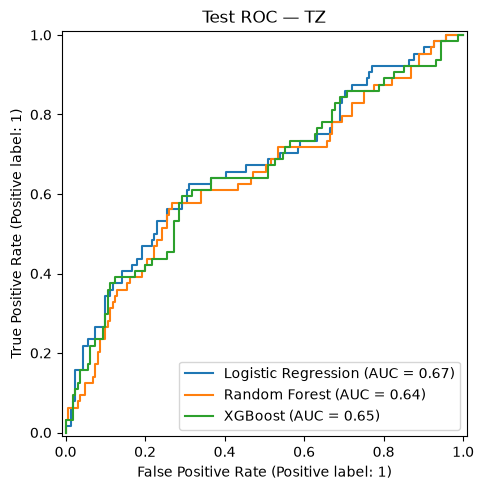

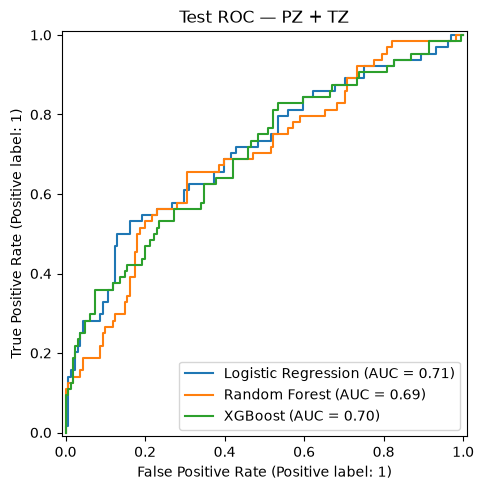

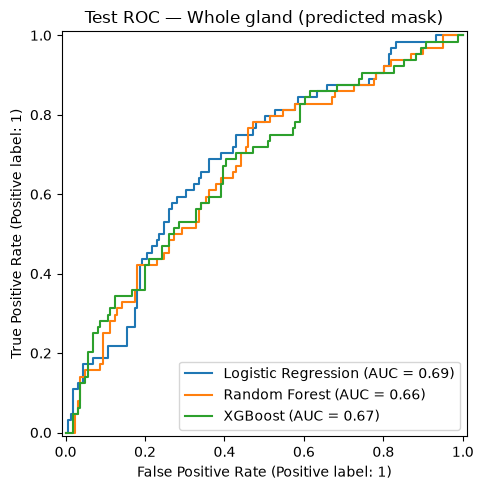

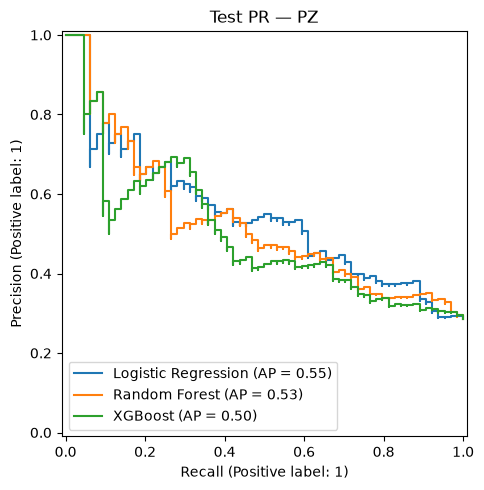

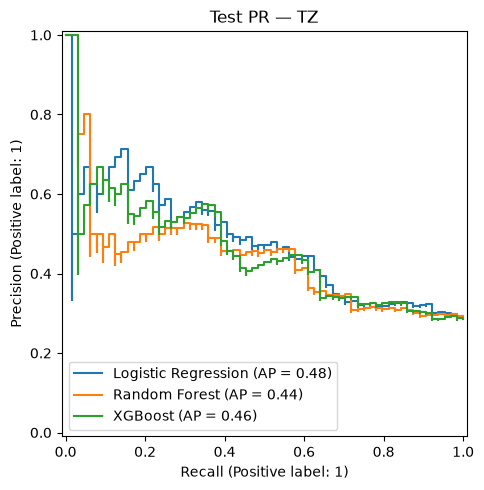

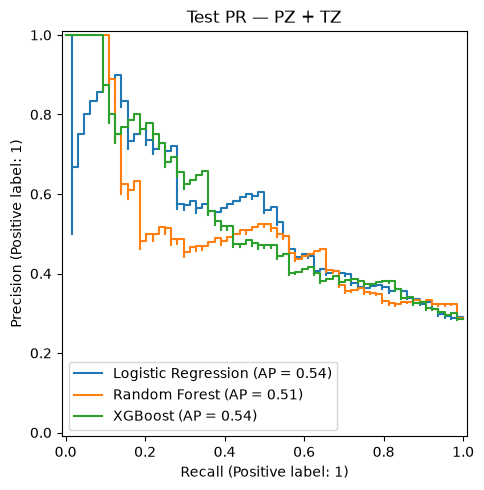

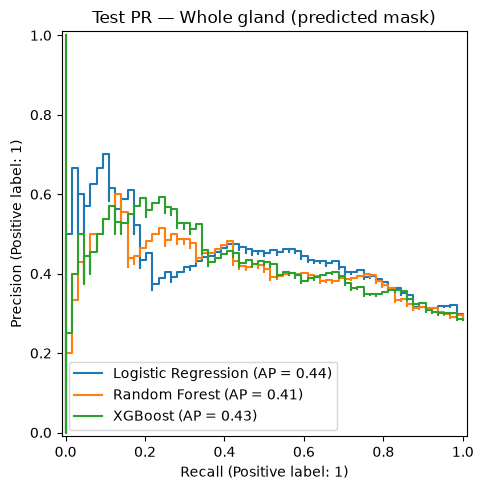

In [8]:
for region_name in feature_groups:
    fig, ax = plt.subplots(figsize=(7, 5))
    for model_name in make_candidates():
        model = selected[(region_name, model_name)]["model"]
        X_test, y_test = datasets[region_name]["test"]
        RocCurveDisplay.from_predictions(y_test, model.predict_proba(X_test)[:, 1], name=model_name, ax=ax)
    ax.set_title(f"Test ROC — {region_name}")
    fig.tight_layout()
    fig.savefig(results_dir / f"roc_{region_name.lower().replace(' ', '_').replace('+', 'plus')}.png", dpi=160)
    plt.show()

for region_name in feature_groups:
    fig, ax = plt.subplots(figsize=(7, 5))
    for model_name in make_candidates():
        model = selected[(region_name, model_name)]["model"]
        X_test, y_test = datasets[region_name]["test"]
        PrecisionRecallDisplay.from_predictions(y_test, model.predict_proba(X_test)[:, 1], name=model_name, ax=ax)
    ax.set_title(f"Test PR — {region_name}")
    fig.tight_layout()
    fig.savefig(results_dir / f"pr_{region_name.lower().replace(' ', '_').replace('+', 'plus')}.png", dpi=160)
    plt.show()

## 8. Save Models and Experimental Results

All files are saved separately from the notebooks 06–07 experiments.

In [9]:
selection_df.to_csv(results_dir / "validation_model_selection.csv", index=False)
metrics_df.to_csv(results_dir / "test_metrics.csv", index=False)
predictions_df.to_csv(results_dir / "test_predictions.csv", index=False)
for (region_name, model_name), info in selected.items():
    slug = (region_name + "_" + model_name).lower().replace(" ", "_").replace("+", "plus").replace("(", "").replace(")", "")
    joblib.dump(info["model"], results_dir / f"{slug}.joblib")
metadata = {
    "random_state": RANDOM_STATE,
    "zonal_features": str(zonal_path),
    "whole_gland_features": str(whole_gland_path),
    "clinical_labels": str(clinical_path),
    "splits": str(splits_path),
    "shared_cohort_cases": len(cohort),
    "regions": {name: len(columns) for name, columns in feature_groups.items()},
    "selection_metric": "validation_roc_auc",
    "threshold_method": "validation_youden_index",
    "mask_provenance": "PZ/TZ reference masks vs whole-gland predicted masks",
    "selected_models": {
        f"{region_name} / {model_name}": {
            "configuration": info["configuration"],
            "validation_roc_auc": float(info["validation_roc_auc"]),
            "threshold": float(info["threshold"]),
            "training_seconds": float(info["training_seconds"]),
        } for (region_name, model_name), info in selected.items()
    },
}
with (results_dir / "experiment_config.json").open("w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2, ensure_ascii=False)
print("Results saved:", results_dir)

Results saved: c:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\results\zonal_classification_grouped_v2


## 9. Interpretation and Limitations

- **Same cases** are used for all four feature representations. If masks are missing, the cohort is smaller than the original 1,500 examinations.
- Clinical labels are case-level; this is not lesion localization.
- Anatomical zonal masks and whole-gland predictions originate from different segmentation procedures. Therefore changes in metrics cannot be attributed solely to the region of interest.
- Hyperparameters and thresholds were selected on the validation partition; testing is a final evaluation only.
- The grouped_v2 full-cohort scores from notebook 07 must **not** be compared directly as if they came from this potentially reduced cohort. Use the whole-gland results recomputed here.
- Reusing an already inspected test set for new exploratory hypotheses limits confirmatory claims. Report these experiments as exploratory.